# 08 — Text Classification Basics (Classical NLP)
## Interview-Oriented Notes + Practical Code

**Goal:** turn text into numbers, build a strong baseline classifier, and understand keyword search (TF-IDF, BM25).
This is the bridge to embeddings and RAG in the GenAI track.

Topics:
- Why classical NLP still matters next to LLMs
- Tokenization, bag of words, n-grams
- TF-IDF
- TF-IDF + Logistic Regression baseline on a real dataset
- Comparing Naive Bayes, Logistic Regression and Linear SVM
- Macro vs micro F1, confusion matrix
- Interpreting the model (top words per class) and error analysis
- Search with TF-IDF + cosine similarity
- BM25 from scratch (keyword search in Lucene / Elasticsearch, and half of hybrid search in RAG)
- Limits of sparse methods → why embeddings
- Stemming vs lemmatization, word2vec vs contextual embeddings
- Practical tricks: character n-grams, hashing, class imbalance
- Classical model vs LLM: when to use which
- Interview cheat sheet

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.metrics.pairwise import cosine_similarity

# NumPy 2.2 + Apple Accelerate prints harmless "encountered in matmul" RuntimeWarnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

pd.set_option("display.width", 140)

# 1. WHY CLASSICAL NLP STILL MATTERS

A TF-IDF + Logistic Regression model:
- trains in seconds and predicts in under a millisecond, at no cost per request
- is explainable (you can list the words that drove a decision)
- is often close to an LLM on **topic / intent classification** when you have a few thousand labeled examples
- runs anywhere (CPU, on-prem, no data leaves the company)

TF-IDF and BM25 are also **keyword search**, which is one half of hybrid search in RAG systems.

**Interview:** "Before reaching for an LLM I build a TF-IDF + Logistic Regression baseline. It tells me how hard
the problem really is, and the LLM has to beat it by enough to justify its cost and latency."

# 2. TEXT → NUMBERS: TOKENIZATION & BAG OF WORDS

Models need numbers. The classical recipe:
1. **Lowercase**
2. **Tokenize:** split into words
3. Optionally remove **stop words** ("the", "is", "and")
4. **Count** each word per document → a **bag of words**: one column per vocabulary word

Word order is lost: "dog bites man" and "man bites dog" get the same vector.

In [2]:
docs = [
    "The model predicts customer churn",
    "Customer churn is costly for the business",
    "The fraud model flags risky payments",
]

count_vec = CountVectorizer()
X_counts = count_vec.fit_transform(docs)
pd.DataFrame(X_counts.toarray(), columns=count_vec.get_feature_names_out(), index=["doc1", "doc2", "doc3"])

,business,churn,costly,customer,flags,for,fraud,is,model,payments,predicts,risky,the
doc1,0,1,0,1,0,0,0,0,1,0,1,0,1
doc2,1,1,1,1,0,1,0,1,0,0,0,0,1
doc3,0,0,0,0,1,0,1,0,1,1,0,1,1


# 3. N-GRAMS & SPARSITY

**n-grams** are sequences of n words. Bigrams (n=2) recover some word order and short phrases:
"customer churn" and "not good" become their own features.

Text matrices are **sparse**: each document uses only a tiny part of the vocabulary,
so scikit-learn stores them as sparse matrices (it keeps only the non-zero values).

In [3]:
bigram_vec = CountVectorizer(ngram_range=(1, 2), stop_words="english")
X_bi = bigram_vec.fit_transform(docs)
print("Features:", list(bigram_vec.get_feature_names_out()))
print(f"\nShape = {X_bi.shape}, non-zero values = {X_bi.nnz}, sparsity = {1 - X_bi.nnz / np.prod(X_bi.shape):.0%}")

Features: ['business', 'churn', 'churn costly', 'costly', 'costly business', 'customer', 'customer churn', 'flags', 'flags risky', 'fraud', 'fraud model', 'model', 'model flags', 'model predicts', 'payments', 'predicts', 'predicts customer', 'risky', 'risky payments']

Shape = (3, 19), non-zero values = 23, sparsity = 60%


# 4. TF-IDF

Raw counts over-weight common words. **TF-IDF** = term frequency × inverse document frequency:

- **TF(t, d):** how often term t appears in document d
- **IDF(t)** = ln((1 + N) / (1 + df(t))) + 1, where N = number of documents and df(t) = documents containing t (scikit-learn's smoothed version)
- Each document vector is then **L2-normalized**, so long documents don't dominate

A word that appears in every document gets a low IDF. A word that is rare but present gets a high weight.

Useful `TfidfVectorizer` options:

| Option | What it does |
|---|---|
| `ngram_range=(1, 2)` | words + bigrams |
| `min_df=2` | drop terms seen in fewer than 2 docs (typos, noise) |
| `max_df=0.9` | drop terms in more than 90% of docs (near stop words) |
| `sublinear_tf=True` | use 1 + log(tf), so the 10th repeat counts less than the first |
| `stop_words="english"` | remove common words (careful: this removes "not") |

In [4]:
tfidf_toy = TfidfVectorizer()
X_tfidf = tfidf_toy.fit_transform(docs)
pd.DataFrame(X_tfidf.toarray(), columns=tfidf_toy.get_feature_names_out(), index=["doc1", "doc2", "doc3"]).round(2)

,business,churn,costly,customer,flags,for,fraud,is,model,payments,predicts,risky,the
doc1,0.00,0.43,0.00,0.43,0.00,0.00,0.00,0.00,0.43,0.00,0.57,0.00,0.34
doc2,0.43,0.32,0.43,0.32,0.00,0.43,0.00,0.43,0.00,0.00,0.00,0.00,0.25
doc3,0.00,0.00,0.00,0.00,0.45,0.00,0.45,0.00,0.34,0.45,0.00,0.45,0.27


In doc1, "the" (in all 3 docs) gets 0.34, "churn" (in 2 docs) gets 0.43, and "predicts" (only in doc1) gets 0.57.

# 5. A REAL DATASET: 20 NEWSGROUPS

Forum posts from 4 topics. We remove **headers, footers and quoted replies**. Without that, the model learns
email addresses and signatures instead of the topic, which is a classic **data leakage** trap in text tasks.

In [5]:
categories = ["comp.graphics", "rec.sport.hockey", "sci.med", "sci.space"]
clean = dict(categories=categories, remove=("headers", "footers", "quotes"), random_state=42)

train = fetch_20newsgroups(subset="train", **clean)
test = fetch_20newsgroups(subset="test", **clean)
labels = [name.split(".")[-1] for name in train.target_names]      # graphics, hockey, med, space

print(f"train = {len(train.data)} posts, test = {len(test.data)} posts\n")
print(pd.Series(train.target).map(dict(enumerate(labels))).value_counts().to_string())
print("\nExample post:\n", " ".join(train.data[1].split())[:400])

train = 2371 posts, test = 1578 posts

hockey      600
med         594
space       593
graphics    584

Example post:
 Derian Hatcher's game-misconduct penalty was rescinded by the NHL, allowing the Minnesota defenseman to play in the North Stars' last two regular-season games. Hatcher was given the penalty during a fight at the end of a loss at St. Louis on Sunday, April 11. But the league didn't rescind the game-misconduct penalty Shane Churla received. The Stars recalled center Cal McGowan from their top minor 


# 6. BASELINE: TF-IDF + LOGISTIC REGRESSION

Put the vectorizer **inside a Pipeline**. The vocabulary and IDF are then learned only from training data,
both here and inside every cross-validation fold, so there is no leakage.

In [6]:
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True, stop_words="english")),
    ("clf", LogisticRegression(max_iter=1000, C=10)),
])
baseline.fit(train.data, train.target)
pred = baseline.predict(test.data)

print(f"Vocabulary size: {len(baseline.named_steps['tfidf'].vocabulary_):,} terms\n")
print(classification_report(test.target, pred, target_names=labels, digits=3))

Vocabulary size: 34,132 terms

              precision    recall  f1-score   support

    graphics      0.901     0.892     0.897       389
      hockey      0.966     0.927     0.946       399
         med      0.899     0.859     0.879       396
       space      0.801     0.878     0.838       394

    accuracy                          0.889      1578
   macro avg      0.892     0.889     0.890      1578
weighted avg      0.892     0.889     0.890      1578



# 7. COMPARE MODELS WITH CROSS-VALIDATION

The three classic text classifiers:

| Model | Why it suits text |
|---|---|
| Multinomial Naive Bayes | Very fast, works with little data, strong baseline |
| Logistic Regression | Fairly well-calibrated probabilities, interpretable weights |
| Linear SVM | Often the most accurate on sparse, high-dimensional text |

Text is high-dimensional (tens of thousands of features), so **linear models are usually enough**.
Tree ensembles rarely beat them on raw TF-IDF.

In [7]:
candidates = {
    "MultinomialNB": MultinomialNB(alpha=0.1),
    "LogisticRegression": LogisticRegression(max_iter=1000, C=10),
    "LinearSVC": LinearSVC(C=0.5),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, clf in candidates.items():
    pipe = make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True, stop_words="english"), clf
    )
    scores = cross_val_score(pipe, train.data, train.target, cv=folds, scoring="f1_macro", n_jobs=-1)
    rows.append({"model": name, "f1_macro (mean)": scores.mean(), "f1_macro (std)": scores.std()})

pd.DataFrame(rows).sort_values("f1_macro (mean)", ascending=False).round(3)

,model,f1_macro (mean),f1_macro (std)
0,MultinomialNB,0.909,0.011
1,LogisticRegression,0.903,0.008
2,LinearSVC,0.902,0.010


All three are within about one point of each other, roughly the fold-to-fold std, so the score alone doesn't pick a winner here.
Choose on other grounds: Logistic Regression gives usable probabilities, and Naive Bayes is the fastest.

# 8. EVALUATION: CONFUSION MATRIX, MACRO vs MICRO F1

- **Macro F1:** average the F1 of each class → every class counts equally (use when small classes matter)
- **Micro F1:** pool all predictions → equals accuracy for single-label problems
- **Weighted F1:** per-class F1 weighted by class size

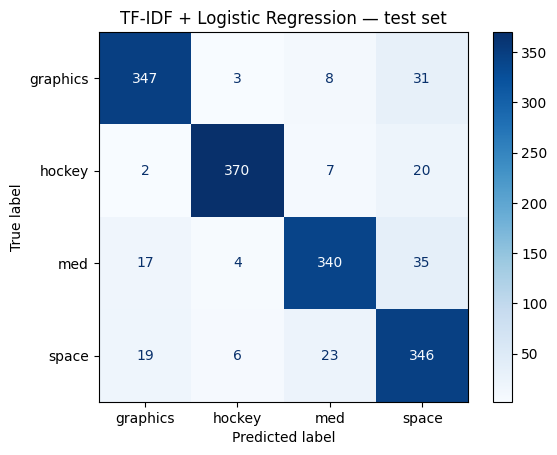

Macro F1 = 0.890
Micro F1 = 0.889  (= accuracy)


In [8]:
ConfusionMatrixDisplay.from_predictions(test.target, pred, display_labels=labels, cmap="Blues")
plt.title("TF-IDF + Logistic Regression — test set")
plt.show()

print(f"Macro F1 = {f1_score(test.target, pred, average='macro'):.3f}")
print(f"Micro F1 = {f1_score(test.target, pred, average='micro'):.3f}  (= accuracy)")

Most errors land in the **space** column, which is why space has the lowest precision. Section 10 finds the cause.

# 9. INTERPRET THE MODEL: TOP WORDS PER CLASS

Logistic Regression has one weight per (class, term). The largest weights show what the model relies on.
This is a quick sanity check: the top words should make sense for the topic.

In [9]:
features = baseline.named_steps["tfidf"].get_feature_names_out()
coefs = baseline.named_steps["clf"].coef_                 # shape: (n_classes, n_features)

for i, name in enumerate(labels):
    top = np.argsort(coefs[i])[-12:][::-1]
    print(f"{name:<9} {', '.join(features[top])}")

graphics  graphics, file, image, 3d, computer, files, hi, images, ftp, card, looking, package
hockey    hockey, game, team, games, season, nhl, play, players, mask, teams, league, pittsburgh
med       doctor, msg, disease, medical, health, pain, treatment, effects, people, cancer, patients, blood
space     space, orbit, moon, nasa, launch, earth, spacecraft, shuttle, solar, dc, lunar, flight


# 10. ERROR ANALYSIS

Read the mistakes. This is the most useful habit in NLP, and later in LLM evals. Typical causes:
very short posts, posts about two topics, or the "wrong" label being reasonable.

In [10]:
proba = baseline.predict_proba(test.data)
wrong = np.where(pred != test.target)[0]
print(f"{len(wrong)} of {len(pred)} test posts misclassified\n")

for i in wrong[:4]:
    text = " ".join(test.data[i].split())
    print(f"TRUE {labels[test.target[i]]:<9} PRED {labels[pred[i]]:<9} confidence {proba[i].max():.2f}   words = {len(text.split())}")
    print("   ", (text[:220] or "<empty post>"), "\n")

175 of 1578 test posts misclassified

TRUE space     PRED med       confidence 0.31   words = 36
    When I went thru all the spinning chair tests at JSC the PhD in charge was Milt Reshke but the technician who strapped me in and, on occasion, inserted the "probe" (needle) was named Bev Bloodworth. 

TRUE hockey    PRED space     confidence 0.32   words = 46
    Nice sig. Like the change. BTW: Could you post the names of the people who are going to be on the letter? I (and I'm sure others) would like to know if we are included. If I'm not I want to be! Roger is a fool! 

TRUE hockey    PRED space     confidence 0.27   words = 0
    <empty post> 

TRUE graphics  PRED space     confidence 0.27   words = 6
    Where can I find it ? 



In [11]:
lengths = np.array([len(t.split()) for t in test.data])
is_wrong = pred != test.target
empty_pred = pd.Series(pred[lengths == 0]).map(dict(enumerate(labels))).value_counts().to_dict()

print(f"Empty test posts: {(lengths == 0).sum()}  → predicted as {empty_pred}")
print(f"Error rate, posts with ≤10 words: {is_wrong[lengths <= 10].mean():.0%}")
print(f"Error rate, longer posts:         {is_wrong[lengths > 10].mean():.0%}")

Empty test posts: 44  → predicted as {'space': 44}
Error rate, posts with ≤10 words: 48%
Error rate, longer posts:         9%


**Finding:** after removing headers and quotes, some posts are empty. With no words the model can only use its
intercepts, so it predicts the same class ("space") for every empty post. Very short posts are almost a coin flip.

Fixes: filter empty inputs before predicting, or send low-confidence predictions (≈ 0.25 = random over 4 classes)
to a fallback or a human. You will do the same with LLM outputs later.

# 11. SEARCH WITH TF-IDF + COSINE SIMILARITY

The same vectors can **rank documents for a query**: turn the query into a TF-IDF vector and sort documents by cosine similarity.

cosine(a, b) = (a · b) / (‖a‖ ‖b‖), from 0 (no shared terms) to 1 (same direction).

This is the "retrieval" step of RAG, in its keyword form.

In [12]:
search_vec = TfidfVectorizer(stop_words="english", sublinear_tf=True)
doc_matrix = search_vec.fit_transform(train.data)


def tfidf_search(query, k=3):
    scores = cosine_similarity(search_vec.transform([query]), doc_matrix).ravel()
    top = np.argsort(scores)[::-1][:k]
    return pd.DataFrame({
        "score": scores[top].round(3),
        "topic": [labels[train.target[i]] for i in top],
        "post": [" ".join(train.data[i].split())[:90] for i in top],
    })


tfidf_search("rocket launch to the moon")

,score,topic,post
0,0.246,space,Suppose the Soviets had managed to get their m...
1,0.188,space,"In fact, you probably want to avoid US Governm..."
2,0.185,space,Why would you want to do that? The goal is to ...


# 12. BM25 FROM SCRATCH

**BM25** is the standard keyword ranking function. It is the default scoring in Lucene, and therefore in
Elasticsearch, OpenSearch and Solr.

score(q, d) = Σ over query terms t of IDF(t) · tf · (k1 + 1) / (tf + k1 · (1 − b + b · |d| / avgdl))

| Part | Meaning |
|---|---|
| IDF(t) = ln((N − df + 0.5) / (df + 0.5) + 1) | rare terms matter more |
| k1 ≈ 1.2–2.0 | **term-frequency saturation**: the 10th mention adds little |
| b ≈ 0.75 | **length normalization**: long documents don't win just by being long |
| \|d\| / avgdl | document length relative to the average |

Compared with TF-IDF cosine: saturation is built in and the length penalty is tunable, which usually gives better search rankings.

In [13]:
class BM25:
    def __init__(self, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.vectorizer = CountVectorizer(stop_words="english")

    def fit(self, docs):
        tf = self.vectorizer.fit_transform(docs).tocsr().astype(float)   # (n_docs, n_terms) raw counts
        n_docs, n_terms = tf.shape
        df = np.bincount(tf.indices, minlength=n_terms)                  # number of docs containing each term
        self.idf = np.log((n_docs - df + 0.5) / (df + 0.5) + 1)
        self.doc_len = np.asarray(tf.sum(axis=1)).ravel()
        self.avgdl = self.doc_len.mean()
        self.tf = tf.tocsc()                                               # fast column (term) access
        self.vocab = self.vectorizer.vocabulary_
        self.analyze = self.vectorizer.build_analyzer()                   # same tokenization as fit
        return self

    def scores(self, query):
        term_ids = {self.vocab[t] for t in self.analyze(query) if t in self.vocab}
        length_norm = self.k1 * (1 - self.b + self.b * self.doc_len / self.avgdl)
        total = np.zeros(self.tf.shape[0])
        for t in term_ids:
            tf = self.tf[:, t].toarray().ravel()
            total += self.idf[t] * tf * (self.k1 + 1) / (tf + length_norm)
        return total


bm25 = BM25().fit(train.data)


def bm25_search(query, k=3):
    scores = bm25.scores(query)
    top = np.argsort(scores)[::-1][:k]
    return pd.DataFrame({
        "score": scores[top].round(2),
        "topic": [labels[train.target[i]] for i in top],
        "post": [" ".join(train.data[i].split())[:90] for i in top],
    })


bm25_search("rocket launch to the moon")

,score,topic,post
0,13.70,space,Suppose the Soviets had managed to get their m...
1,11.98,space,"In fact, you probably want to avoid US Governm..."
2,11.28,space,"In fact, you can all direct your ire at the pr..."


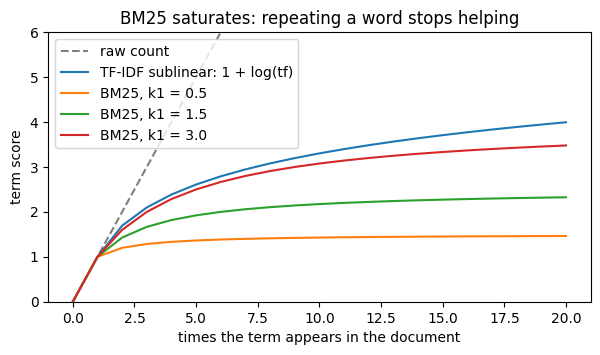

In [14]:
# Term-frequency saturation: how much the k-th occurrence of a word adds (document of average length)
tf = np.arange(0, 21)
plt.figure(figsize=(7, 3.5))
plt.plot(tf, tf, "--", color="gray", label="raw count")
plt.plot(tf, np.where(tf > 0, 1 + np.log(np.maximum(tf, 1)), 0), label="TF-IDF sublinear: 1 + log(tf)")
for k1 in [0.5, 1.5, 3.0]:
    plt.plot(tf, tf * (k1 + 1) / (tf + k1), label=f"BM25, k1 = {k1}")
plt.ylim(0, 6)
plt.xlabel("times the term appears in the document")
plt.ylabel("term score")
plt.legend()
plt.title("BM25 saturates: repeating a word stops helping")
plt.show()

**Hybrid search (RAG preview):** BM25 is good at exact words, product codes, error IDs and rare names.
Embeddings are good at meaning and synonyms. Production RAG systems usually run both and merge the two
rankings, for example with *reciprocal rank fusion*.

# 13. LIMITS OF SPARSE METHODS → EMBEDDINGS

Bag-of-words only matches **identical tokens**:
- Synonyms don't match: "car" vs "automobile"
- Word order and negation are mostly lost
- The vocabulary is fixed when you train, so new words are ignored

**Dense embeddings** (sentence-transformers, LLM embedding APIs) map text to vectors where similar *meaning*
gives similar vectors. That is the first topic of the GenAI track.

In [15]:
pair = ["my car broke down", "the automobile needs repair"]
m = TfidfVectorizer().fit_transform(pair)
print(f"TF-IDF cosine similarity = {cosine_similarity(m[0], m[1])[0, 0]:.2f}   (same meaning, no shared words)")

TF-IDF cosine similarity = 0.00   (same meaning, no shared words)


# 14. STEMMING, LEMMATIZATION AND WORD2VEC

**Stemming vs lemmatization** both map word forms to one base, which shrinks the vocabulary for TF-IDF and BM25
(the Lucene and Elasticsearch analyzers apply stemming):

| | Stemming | Lemmatization |
|---|---|---|
| How | chops suffixes with rules (Porter, Snowball) | looks up the dictionary form, using the part of speech |
| Example | "studies" → "studi", "running" → "run" | "studies" → "study", "better" → "good" |
| Gain | fast, no dictionary needed | real words, more accurate |
| Cost | crude: produces non-words and can merge unrelated words | slower; needs a dictionary and a tagger (spaCy, NLTK WordNet) |

Embedding models and LLMs use subword tokenizers instead and need neither.

**word2vec** learns a dense vector per word (for example 300 numbers) by predicting neighbouring words:
skip-gram predicts the context from a word, CBOW predicts a word from its context. Words used in similar contexts get similar vectors,
which gives the famous analogy king − man + woman ≈ queen.
Its limit: the vectors are **static**, one per word in every sentence, so "bank" (river) and "bank" (money) are the same vector.
Transformer models (BERT, sentence-transformers) produce **contextual** embeddings that depend on the whole sentence; those are what RAG and semantic search use.

| | TF-IDF / BM25 | word2vec (static) | Contextual embeddings |
|---|---|---|---|
| Captures | exact words | word similarity | the meaning of the whole text |
| Gain | fast, explainable, exact matches for IDs, names and codes | synonyms get close vectors; small and fast | the best semantic search quality |
| Cost | misses synonyms and paraphrases | one meaning per word; averaging a sentence loses word order | needs a model (and a GPU for large corpora); less explainable |
| Use it for | keyword search, baselines, half of hybrid search | older systems, quick features | RAG, semantic search, clustering texts |

# 15. PRACTICAL TRICKS

| Problem | Fix |
|---|---|
| Typos, misspellings, morphology | Character n-grams: `TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))` |
| Vocabulary too big for memory, streaming data | `HashingVectorizer` (no stored vocabulary) |
| Imbalanced classes | `class_weight="balanced"`, macro F1 / PR-AUC |
| Negation matters (sentiment) | Keep stop words like "not", use bigrams |
| Model too large | `max_features`, `min_df` |
| Multi-label (a post can have many tags) | `OneVsRestClassifier` + `MultiLabelBinarizer` |

In [16]:
pair = ["rocket launch delayed", "rocket lanuch delayed"]          # typo in the second text
for name, vec in [("word TF-IDF", TfidfVectorizer()),
                  ("char 3-5-gram", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)))]:
    m = vec.fit_transform(pair)
    print(f"{name:<14} cosine similarity = {cosine_similarity(m[0], m[1])[0, 0]:.2f}")

word TF-IDF    cosine similarity = 0.50
char 3-5-gram  cosine similarity = 0.58


# 16. CLASSICAL MODEL vs LLM — WHEN TO USE WHICH

| Situation | Prefer |
|---|---|
| Thousands of labeled examples, fixed set of classes | TF-IDF / embeddings + linear model |
| Very high volume, strict latency, or cost limits | Classical model |
| No labeled data yet, or classes change often | LLM zero-shot / few-shot |
| Nuanced reasoning, long context, open-ended output | LLM |
| Must explain each decision, or must run on-prem | Classical model |

**Middle ground used in practice:**
1. **Embeddings + Logistic Regression:** semantic features with a cheap classifier
2. **LLM as labeler:** label a few thousand examples with an LLM, check a sample by hand, then train a cheap classifier (distillation)
3. **Cascade:** classical model first; send only low-confidence cases to the LLM

# 17. PREDICT ON NEW TEXT

Because the vectorizer is inside the Pipeline, raw text goes in and a label comes out.
Save the **whole pipeline** with `joblib.dump(baseline, "text_clf.joblib")`, exactly as in `6-ml-deployments`.

In [17]:
new_posts = [
    "The shuttle reached orbit after a smooth launch",
    "Great save by the goalie in overtime",
    "Which file format should I use for 3D rendering?",
    "The doctor prescribed antibiotics for the infection",
]
for text, label, p in zip(new_posts, baseline.predict(new_posts), baseline.predict_proba(new_posts).max(axis=1)):
    print(f"{labels[label]:<9} ({p:.2f})  ← {text}")

space     (0.99)  ← The shuttle reached orbit after a smooth launch
hockey    (0.52)  ← Great save by the goalie in overtime
graphics  (0.99)  ← Which file format should I use for 3D rendering?
med       (0.94)  ← The doctor prescribed antibiotics for the infection


# 18. COMMON MISTAKES

1. Fitting the vectorizer on all data before splitting (leakage). Keep it inside the Pipeline.
2. Leaving metadata in the text (headers, signatures, IDs), so the model learns the source and not the content.
3. Removing stop words in tasks where "not" or "no" changes the meaning.
4. Reporting accuracy on imbalanced classes instead of macro F1 / PR-AUC.
5. Judging the model on one split; use cross-validation.
6. Never reading the misclassified examples.
7. Jumping to an LLM without a baseline to compare against.

# 19. INTERVIEW CHEAT SHEET

### What is bag of words?
Each document becomes a vector of word counts over the vocabulary. Word order is lost.

### What is TF-IDF?
Term frequency × inverse document frequency. It down-weights words that appear everywhere.

### Why sublinear TF?
1 + log(tf) stops a document from winning just by repeating a word.

### Best baseline for text classification?
TF-IDF (word 1–2 grams) + Logistic Regression or Linear SVM, inside a Pipeline.

### Why do linear models work well on text?
Text features are high-dimensional and sparse, and classes are often close to linearly separable in that space.

### Macro vs micro F1?
Macro = mean of per-class F1, so every class counts equally. Micro = pooled, which equals accuracy for single-label problems.

### What is BM25?
A keyword ranking function with IDF, term-frequency saturation (k1) and length normalization (b). It is Lucene's default.

### TF-IDF cosine vs BM25?
Both are sparse keyword methods. BM25 adds saturation and tunable length normalization, and usually ranks better for search.

### Limits of TF-IDF / BM25?
No synonyms or meaning, and a fixed vocabulary. Dense embeddings fix this; hybrid search combines both.

### When would you NOT use an LLM for classification?
High volume, strict latency or cost limits, plenty of labeled data, a need for explainability, or on-prem requirements.

# 20. FINAL MENTAL MODEL

```text
                    Raw text
                       |
          lowercase → tokenize → (stop words) → n-grams
                       |
            ┌──────────┴──────────┐
            ↓                     ↓
     Count / TF-IDF           BM25 scores
     (sparse vectors)         (query vs docs)
            |                     |
     Linear classifier        Keyword search
     (LogReg / SVM / NB)          |
            |                     ↓
     macro F1, confusion      Hybrid search with
     matrix, error analysis   embeddings (RAG) → GenAI track
```

Remember:

- Pipeline(TF-IDF → linear model) = the baseline every text model must beat
- Remove metadata to avoid leakage
- BM25 = keyword retrieval, embeddings = semantic retrieval
- Read the errors